<a href="https://colab.research.google.com/github/yaserabutair-dev/olist-delivery-delay-analysis/blob/main/olist_delivery_delay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import kagglehub

path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print(path)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
/kaggle/input/brazilian-ecommerce


In [4]:
import pandas as pd

orders = pd.read_csv(path + "/olist_orders_dataset.csv")
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
orders["order_delivered_customer_date"] = pd.to_datetime(orders["order_delivered_customer_date"])
orders["order_estimated_delivery_date"] = pd.to_datetime(orders["order_estimated_delivery_date"])

df = orders[orders["order_status"] == "delivered"]
df = df.dropna(subset=["order_delivered_customer_date"])

print("عدد كل الطلبات:", len(orders))
print("عدد الطلبات اللي وصلت:", len(df))

عدد كل الطلبات: 99441
عدد الطلبات اللي وصلت: 96470


In [6]:
df["delay_days"] = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.days
df["is_late"] = df["delay_days"] > 0

print("نسبة الطلبات المتأخرة:", round(df["is_late"].mean() * 100, 1), "%")

نسبة الطلبات المتأخرة: 6.8 %


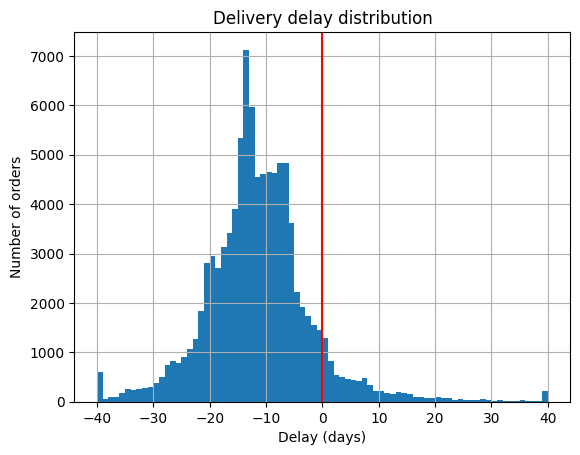

In [7]:
import matplotlib.pyplot as plt

df["delay_days"].clip(-40, 40).hist(bins=80)
plt.axvline(0, color="red")
plt.xlabel("Delay (days)")
plt.ylabel("Number of orders")
plt.title("Delivery delay distribution")
plt.show()

In [8]:
print("متوسط الفرق عن الموعد:", round(df["delay_days"].median()), "يوم")

متوسط الفرق عن الموعد: -12 يوم


In [9]:
reviews = pd.read_csv(path + "/olist_order_reviews_dataset.csv")

merged = df.merge(reviews[["order_id", "review_score"]], on="order_id")

merged.groupby("is_late")["review_score"].mean().round(2)

,review_score
is_late,
False,4.29
True,2.27


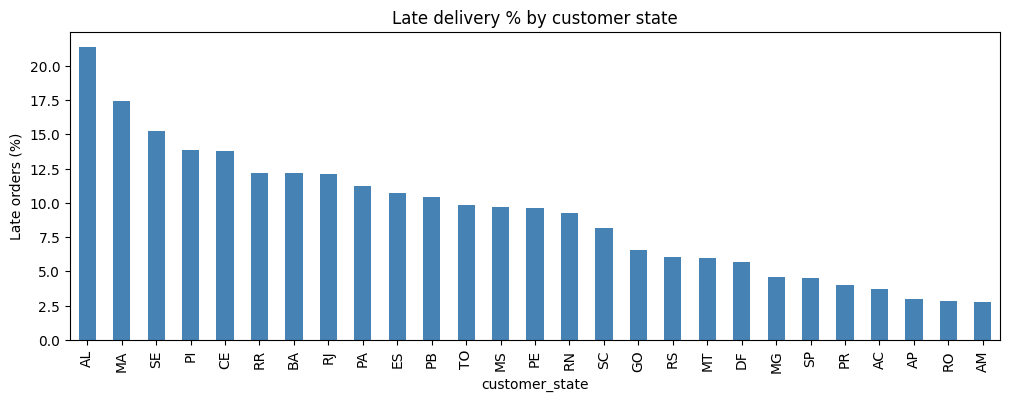

In [10]:
customers = pd.read_csv(path + "/olist_customers_dataset.csv")

merged2 = df.merge(customers[["customer_id", "customer_state"]], on="customer_id")

by_state = merged2.groupby("customer_state")["is_late"].mean() * 100
by_state = by_state.sort_values(ascending=False)

by_state.plot(kind="bar", figsize=(12, 4), color="steelblue")
plt.ylabel("Late orders (%)")
plt.title("Late delivery % by customer state")
plt.show()


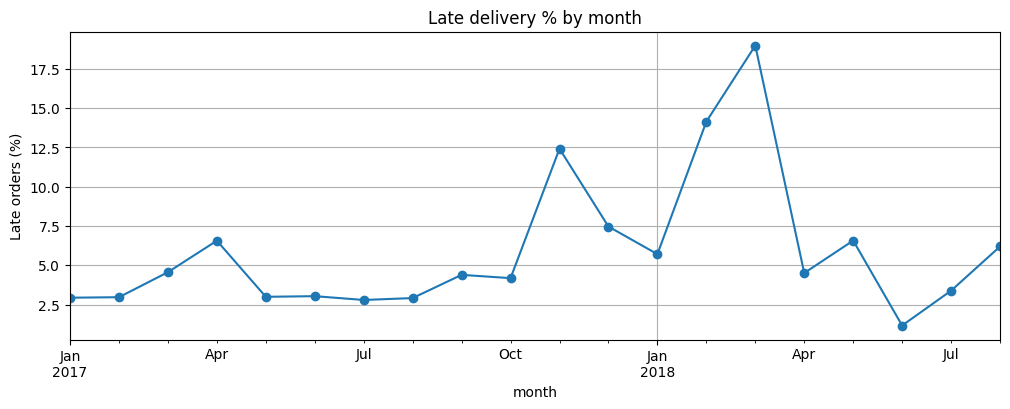

In [11]:
df["order_purchase_timestamp"] = pd.to_datetime(df["order_purchase_timestamp"])
df["month"] = df["order_purchase_timestamp"].dt.to_period("M")

by_month = df.groupby("month")["is_late"].mean() * 100
by_month = by_month["2017-01":"2018-08"]

by_month.plot(marker="o", figsize=(12, 4))
plt.ylabel("Late orders (%)")
plt.title("Late delivery % by month")
plt.grid(True)
plt.show()